# Ajuste de hiperparámetros, particiones temporales y arranque en frío estricto

Antes de cerrar la conclusión de que ningún modelo supera con firmeza a su línea base hay que descartar dos objeciones:

1. **¿Rinden poco por usar hiperparámetros por defecto?** → ajuste con **validación anidada** (sin fuga).
2. **¿La validación por IES representa el uso real?** → **particiones temporales** (años futuros y pandemia) y **arranque en frío estricto**
   (pliegues por municipio, para que ninguna ciudad de prueba esté en el entrenamiento).

Los cálculos pesados los hace `desercion evaluar ajuste` y se guardan en `reports/tables/`. Aquí se leen y se muestran; lo único que se
calcula en el cuaderno es una **ilustración** de la validación anidada sobre un pliegue.

In [1]:
# Configuración: rutas relativas a la raíz del proyecto, librerías y avisos
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "configs" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from desercion_ies.config import load_config
from desercion_ies.evaluation import ajuste as aj
from desercion_ies.evaluation import arranque_frio as af
from desercion_ies.evaluation import tarea2 as t2
from desercion_ies.evaluation import temporal as tp
from desercion_ies.evaluation.experimentos import parametros_experimentos
from desercion_ies.features.particion import cargar_dataset
from desercion_ies.evaluation.protocolo import particiones_repetidas

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
cfg = load_config()
p = aj.parametros_ajuste(cfg)
R = Path("reports/tables")
print("Semillas externas:", p["semillas_externas"], "| búsqueda interna:", p["n_iter"], "iteraciones, GroupKFold de", p["n_splits_interno"], "pliegues")

Semillas externas: [301, 302, 303, 304, 305] | búsqueda interna: 30 iteraciones, GroupKFold de 3 pliegues


## 1. Validación anidada: cómo funciona (ilustrado en un pliegue)

- **Externa:** GroupKFold por IES. El pliegue de prueba externo **no se toca** hasta la medición final.
- **Interna:** sobre el entrenamiento externo, una búsqueda aleatoria de 30 iteraciones evalúa cada combinación con GroupKFold por IES de 3 pliegues.
- El mejor modelo se reajusta con todo el entrenamiento externo y se mide en la prueba externa. Se compara con el de hiperparámetros por defecto en el mismo pliegue.

Ilustración con la configuración más rápida de la Tarea 1 (C solo historia, xgboost):

In [2]:
# Un pliegue externo (semilla 301) y la configuración T1 C solo historia | xgboost
df = cargar_dataset(cfg)
y, grupos = df["tasa_desercion"].astype(float), df["cod_ies"].astype(str).to_numpy()
spec = next(s for s in aj.configuraciones_ajuste(cfg) if s["nombre"] == "T1 C solo historia | xgboost")
X, numericas, categoricas = aj.preparar(spec, cfg, df)
entrena, prueba = particiones_repetidas(df, p["n_splits_externo"], [p["semillas_externas"][0]])[0][0]
print(f"Entrenamiento externo: {len(entrena)} filas, {len(set(grupos[entrena]))} IES | prueba externa: {len(prueba)} filas, {len(set(grupos[prueba]))} IES")
print("IES compartidas entre entrenamiento y prueba externos:", len(set(grupos[entrena]) & set(grupos[prueba])))

# La búsqueda recibe SOLO el entrenamiento externo (y sus IES)
p_exp, p_t2 = parametros_experimentos(cfg), t2.parametros_tarea2(cfg)
est, dist = aj.estimador_ajustable(aj.construir_estimador(spec, numericas, categoricas, p_exp, p_t2), spec, p["k_info_mutua"])
busqueda, t_busqueda = aj.buscar(est, dist, X.iloc[entrena], y.iloc[entrena].to_numpy(), grupos[entrena], p)
print(f"Búsqueda interna: {t_busqueda:.1f} s; filas vistas por la búsqueda: {len(busqueda.cv_results_['params'])} combinaciones x {p['n_splits_interno']} pliegues internos")

Entrenamiento externo: 1545 filas, 236 IES | prueba externa: 383 filas, 59 IES
IES compartidas entre entrenamiento y prueba externos: 0


Búsqueda interna: 8.2 s; filas vistas por la búsqueda: 30 combinaciones x 3 pliegues internos


In [3]:
# Las 5 mejores combinaciones de la búsqueda interna (MAE interno) y el resultado en la prueba externa
cv = pd.DataFrame(busqueda.cv_results_)
cv["mae_interno"] = -cv["mean_test_score"]
cols = [c for c in cv.columns if c.startswith("param_")] + ["mae_interno"]
display(cv.sort_values("mae_interno")[cols].head(5).rename(columns=lambda c: c.replace("param_regressor__modelo__", "").replace("param_modelo__", "")))
d, a = aj.ajustar_y_evaluar(spec, X, y, grupos, entrena, prueba, numericas, categoricas, p_exp, p_t2, p)
real = y.iloc[prueba].to_numpy()
print(f"MAE en la prueba externa: por defecto {np.mean(np.abs(d['pred'] - real)):.4f} | ajustado {np.mean(np.abs(a['pred'] - real)):.4f}")
print("Hiperparámetros elegidos:", a["hiperparametros"])

,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample,mae_interno
9,0.8000,0.0203,6,5,200,8.6930,1.0000,0.0240
8,1.0000,0.0180,2,5,500,3.2413,1.0000,0.0241
25,0.8000,0.0145,2,10,500,0.1002,0.7000,0.0241
11,0.8000,0.0195,2,5,500,4.8873,0.7000,0.0241
7,0.5000,0.0106,3,10,500,0.1754,0.7000,0.0242


MAE en la prueba externa: por defecto 0.0275 | ajustado 0.0275
Hiperparámetros elegidos: {"colsample_bytree": 0.8, "learning_rate": 0.02028406763400795, "max_depth": 6, "min_child_weight": 5, "n_estimators": 200, "reg_lambda": 8.692991511139551, "subsample": 1.0}


## 2. Por defecto frente a ajustado (25 ajustes externos por configuración)

Tabla completa en el informe. «Mejora por el ajuste» = MAE por defecto − MAE ajustado. La línea base es la ingenua (Tarea 1) o la mediana por
carácter × sector (Tarea 2). IC 95 % y «t corregida» de Nadeau y Bengio.

Tarea 1 (línea base: ingenua)


,configuracion,variante,mae_media,mae_ic_inf,mae_ic_sup,mejora_base_pct,p_wilcoxon_base,p_t_base,gana_base
0,T1 base_ingenua,linea_base,0.0256,0.0225,0.0288,0.0000,NaN,NaN,0.0000
1,T1 base_mediana,linea_base,0.0501,0.0441,0.0560,-95.3556,0.0000,0.0000,0.0000
2,T1 C solo historia | ridge,defecto,0.0245,0.0211,0.0279,4.2286,0.0000,0.0364,0.8800
3,T1 C solo historia | ridge,ajustado,0.0245,0.0212,0.0278,4.4104,0.0000,0.0112,0.9600
4,T1 C solo historia | random_forest,defecto,0.0257,0.0221,0.0293,-0.4172,0.7510,0.9054,0.4800
5,T1 C solo historia | random_forest,ajustado,0.0245,0.0212,0.0279,4.3205,0.0000,0.0566,0.8800
6,T1 C solo historia | xgboost,defecto,0.0257,0.0218,0.0296,-0.3105,0.7712,0.9338,0.4400
7,T1 C solo historia | xgboost,ajustado,0.0250,0.0215,0.0286,2.2882,0.0203,0.3589,0.7200
8,T1 B historia+contexto | xgboost logit,defecto,0.0258,0.0218,0.0299,-0.7629,0.8532,0.8573,0.4800
9,T1 B historia+contexto | xgboost logit,ajustado,0.0250,0.0211,0.0288,2.6322,0.0802,0.4961,0.6400


Tarea 2 (línea base: mediana por carácter × sector)


,configuracion,variante,mae_media,mae_ic_inf,mae_ic_sup,mejora_base_pct,p_wilcoxon_base,p_t_base,gana_base
0,T2 base_mediana_grupo,linea_base,0.0400,0.0345,0.0455,0.0000,NaN,NaN,0.0000
1,T2 base_mediana,linea_base,0.0501,0.0441,0.0560,-25.1831,0.0000,0.0000,0.0000
2,T2 | ridge | logit | mediana | info_mutua | sin clusters,defecto,0.0396,0.0343,0.0448,1.0877,0.0903,0.5621,0.6800
3,T2 | ridge | logit | mediana | info_mutua | sin clusters,ajustado,0.0396,0.0345,0.0448,0.9353,0.1266,0.5962,0.6800
4,T2 | xgboost | logit | mediana | ninguna | con clusters,defecto,0.0448,0.0393,0.0504,-12.0778,0.0000,0.0014,0.0000
5,T2 | xgboost | logit | mediana | ninguna | con clusters,ajustado,0.0407,0.0355,0.0458,-1.6617,0.0957,0.5222,0.3600
6,T2 | random_forest | logit | mediana | ninguna | con clusters,defecto,0.0469,0.0414,0.0523,-17.1460,0.0000,0.0002,0.0000
7,T2 | random_forest | logit | mediana | ninguna | con clusters,ajustado,0.0398,0.0348,0.0449,0.4472,0.4742,0.8045,0.6000


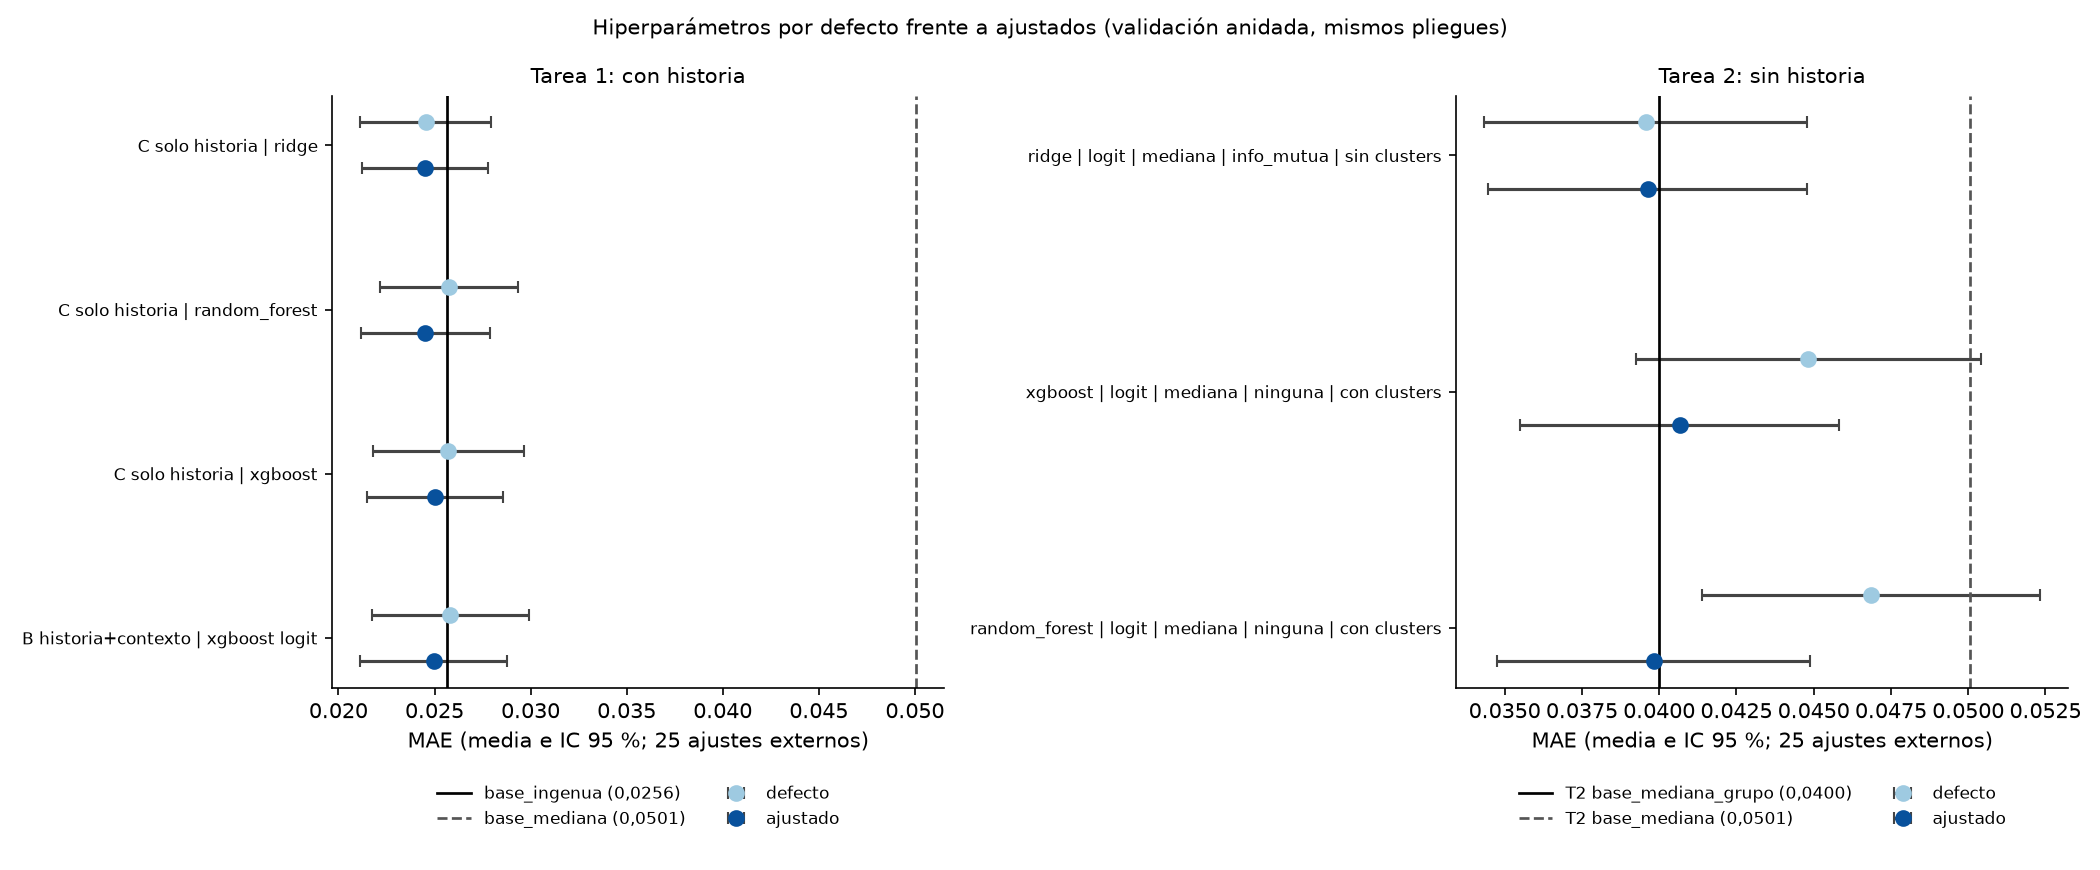

In [4]:
r = pd.read_csv(R / "ajuste_resumen.csv")
cols = ["configuracion", "variante", "mae_media", "mae_ic_inf", "mae_ic_sup", "mejora_base_pct", "p_wilcoxon_base", "p_t_base", "gana_base"]
for tarea, titulo in (("T1", "Tarea 1 (línea base: ingenua)"), ("T2", "Tarea 2 (línea base: mediana por carácter × sector)")):
    print(titulo)
    display(r[(r.tarea == tarea)][cols].reset_index(drop=True))
display(Image("reports/figures/ajuste_vs_defecto.png"))

In [5]:
# Hiperparámetros más elegidos en los pliegues externos y tiempos de ajuste/predicción/búsqueda (para el análisis de complejidad)
display(pd.read_csv(R / "ajuste_hiperparametros.csv"))
display(r[r.variante != "linea_base"][["configuracion", "variante", "t_ajuste_media_s", "t_prediccion_media_s", "t_busqueda_media_s"]].reset_index(drop=True))

,configuracion,hiperparametro,resumen,n
0,T1 C solo historia | ridge,alpha,mediana 157.4 (rango 98.78–506.2),25
1,T1 C solo historia | random_forest,max_depth,None (13 de 25),25
2,T1 C solo historia | random_forest,max_features,sqrt (13 de 25),25
3,T1 C solo historia | random_forest,min_samples_leaf,10 (15 de 25),25
4,T1 C solo historia | random_forest,n_estimators,500 (21 de 25),25
5,T1 C solo historia | xgboost,colsample_bytree,0.8 (11 de 25),25
6,T1 C solo historia | xgboost,learning_rate,mediana 0.02028 (rango 0.01056–0.05426),25
7,T1 C solo historia | xgboost,max_depth,6 (8 de 25),25
8,T1 C solo historia | xgboost,min_child_weight,1 (15 de 25),25
9,T1 C solo historia | xgboost,n_estimators,200 (21 de 25),25


,configuracion,variante,t_ajuste_media_s,t_prediccion_media_s,t_busqueda_media_s
0,T1 C solo historia | ridge,defecto,0.3543,0.0093,NaN
1,T1 C solo historia | ridge,ajustado,0.0170,0.0063,3.0552
2,T1 C solo historia | random_forest,defecto,3.6728,0.1086,NaN
3,T1 C solo historia | random_forest,ajustado,1.8466,0.1137,115.2442
4,T1 C solo historia | xgboost,defecto,0.9298,0.0159,NaN
5,T1 C solo historia | xgboost,ajustado,0.2265,0.0140,23.4775
6,T1 B historia+contexto | xgboost logit,defecto,1.3638,0.0347,NaN
7,T1 B historia+contexto | xgboost logit,ajustado,0.5883,0.0265,96.9743
8,T2 | ridge | logit | mediana | info_mutua | sin clusters,defecto,0.8947,0.0250,NaN
9,T2 | ridge | logit | mediana | info_mutua | sin clusters,ajustado,0.8000,0.0212,57.5440


## 3. Particiones temporales

- **Prepandemia:** entrena 2015–2017, prueba 2018–2019. **Estrés:** entrena 2015–2019, prueba 2020–2021.
- En cada partición se re-ajusta con la búsqueda interna **solo con los años de entrenamiento**.
- **Tarea 1 es un pronóstico a un paso:** para predecir t se usa la tasa observada de t-1, aunque t-1 esté en el período de prueba (en la práctica está disponible).
- IC 95 % por bootstrap sobre IES (1.000 réplicas, semilla fija); las diferencias con la línea base son pareadas.

,particion,tarea,configuracion,variante,mae,mae_ic_inf,mae_ic_sup,rmse,r2,dif_ref,dif_ref_ic_inf,dif_ref_ic_sup,prop_gana_ref
0,prepandemia,T1,T1 base_ingenua,linea_base,0.0226,0.0188,0.0269,0.0471,0.6322,0.0000,0.0000,0.0000,0.0000
1,prepandemia,T1,T1 base_mediana,linea_base,0.0440,0.0373,0.0520,0.0784,-0.0192,-0.0214,-0.0271,-0.0161,0.0000
2,prepandemia,T1,T1 C solo historia | ridge,ajustado,0.0214,0.0179,0.0254,0.0425,0.7002,0.0012,-0.0002,0.0026,0.9550
3,prepandemia,T1,T1 C solo historia | random_forest,ajustado,0.0228,0.0193,0.0268,0.0454,0.6586,-0.0002,-0.0019,0.0015,0.4540
4,prepandemia,T1,T1 C solo historia | xgboost,ajustado,0.0235,0.0198,0.0275,0.0463,0.6444,-0.0008,-0.0023,0.0006,0.1440
5,prepandemia,T1,T1 B historia+contexto | xgboost logit,ajustado,0.0231,0.0193,0.0277,0.0475,0.6255,-0.0005,-0.0028,0.0018,0.3350
6,prepandemia,T2,T2 base_mediana_grupo,linea_base,0.0355,0.0306,0.0420,0.0643,0.3159,0.0000,0.0000,0.0000,0.0000
7,prepandemia,T2,T2 base_mediana,linea_base,0.0440,0.0373,0.0520,0.0784,-0.0192,-0.0085,-0.0120,-0.0050,0.0000
8,prepandemia,T2,T2 | ridge | logit | mediana | info_mutua | sin clusters,ajustado,0.0642,0.0573,0.0723,0.1060,-0.8620,-0.0287,-0.0355,-0.0224,0.0000
9,prepandemia,T2,T2 | xgboost | logit | mediana | ninguna | con clusters,ajustado,0.0335,0.0289,0.0395,0.0601,0.4010,0.0020,0.0002,0.0040,0.9870


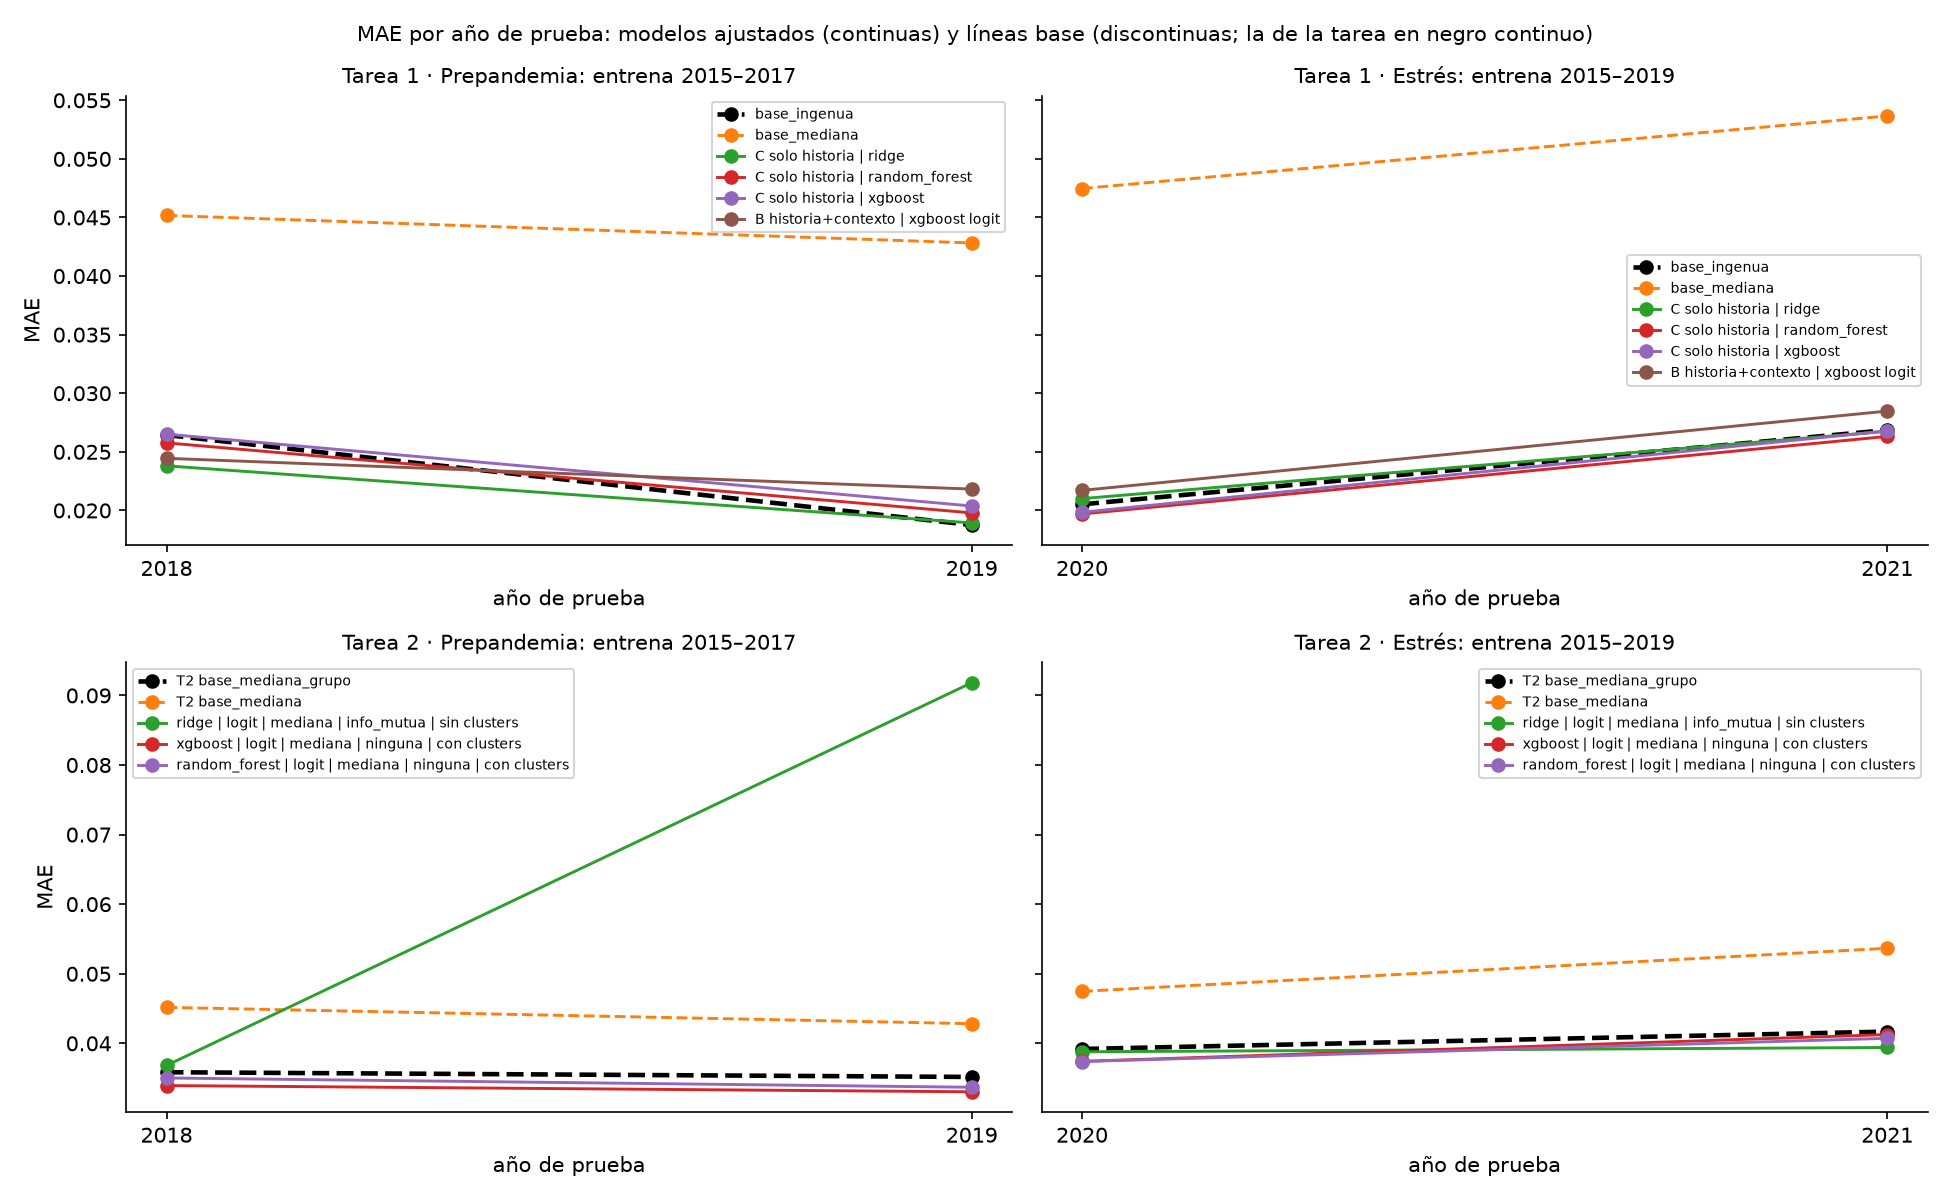

In [6]:
tm = pd.read_csv(R / "temporal.csv")
cols = ["particion", "tarea", "configuracion", "variante", "mae", "mae_ic_inf", "mae_ic_sup", "rmse", "r2", "dif_ref", "dif_ref_ic_inf", "dif_ref_ic_sup", "prop_gana_ref"]
display(tm[tm.variante.isin(["ajustado", "linea_base"])][cols].reset_index(drop=True))
display(Image("reports/figures/temporal_por_anio.png"))

In [7]:
# Degradación en 2020–2021: razón entre el MAE del estrés y el de la prepandemia (los entrenamientos son distintos)
g = tm[tm.variante.isin(["ajustado", "linea_base"])]
a, b = g[g.particion == "prepandemia"].set_index("configuracion"), g[g.particion == "estres"].set_index("configuracion")
degr = pd.DataFrame({"tarea": a.tarea, "mae_prepandemia": a.mae, "mae_estres": b.mae, "razon": b.mae / a.mae}).sort_values(["tarea", "razon"], ascending=[True, False])
display(degr)

,tarea,mae_prepandemia,mae_estres,razon
configuracion,,,,
T1 base_mediana,T1,0.0440,0.0506,1.1488
T1 C solo historia | ridge,T1,0.0214,0.0239,1.1164
T1 B historia+contexto | xgboost logit,T1,0.0231,0.0251,1.0838
T1 base_ingenua,T1,0.0226,0.0237,1.0469
T1 C solo historia | random_forest,T1,0.0228,0.0230,1.0088
T1 C solo historia | xgboost,T1,0.0235,0.0233,0.9934
T2 | xgboost | logit | mediana | ninguna | con clusters,T2,0.0335,0.0393,1.1744
T2 base_mediana,T2,0.0440,0.0506,1.1488
T2 base_mediana_grupo,T2,0.0355,0.0404,1.1386


In [8]:
# Error por sector, carácter y año de prueba (MAE) de los modelos ajustados y las líneas base
gr = pd.read_csv(R / "temporal_grupos.csv")
gr = gr[gr.variante.isin(["ajustado", "linea_base"])]
for (part, tarea), x in gr.groupby(["particion", "tarea"]):
    print(f"--- {part} · {tarea}")
    display(x.pivot_table(index="configuracion", columns=["variable", "nivel"], values="mae"))

--- estres · T1


variable                                 anio        bogota                         caracter                                              sector        
nivel                                    2020   2021 Bogotá  resto institución universitaria tecnológica técnica profesional universidad oficial privada
configuracion                                                                                                                                           
T1 B historia+contexto | xgboost logit 0.0217 0.0285 0.0300 0.0229                    0.0230      0.0511              0.0694      0.0136  0.0205  0.0268
T1 C solo historia | random_forest     0.0197 0.0263 0.0248 0.0222                    0.0203      0.0496              0.0632      0.0125  0.0206  0.0239
T1 C solo historia | ridge             0.0210 0.0268 0.0263 0.0228                    0.0211      0.0508              0.0657      0.0131  0.0199  0.0254
T1 C solo historia | xgboost           0.0198 0.0268 0.0249 0.0226                    0.0204      0.0499              0.0668      0.0125  0.0208  0.0242
T1 base_ingenua                        0.0205 0.0269 0.0254 0.0229                    0.0214      0.0474              0.0678      0.0129  0.0234  0.0238
T1 base_mediana                        0.0475 0.0537 0.0671 0.0432                    0.0389      0.1025              0.1299      0.0357  0.0418  0.0538

--- estres · T2


variable                                                        anio        bogota                         caracter                                              sector        
nivel                                                           2020   2021 Bogotá  resto institución universitaria tecnológica técnica profesional universidad oficial privada
configuracion                                                                                                                                                                  
T2 base_mediana                                               0.0475 0.0537 0.0671 0.0432                    0.0389      0.1025              0.1299      0.0357  0.0418  0.0538
T2 base_mediana_grupo                                         0.0392 0.0417 0.0536 0.0346                    0.0390      0.0759              0.0895      0.0253  0.0341  0.0428
T2 | random_forest | logit | mediana | ninguna | con clusters 0.0374 0.0407 0.0524 0.0331                    0.0378      0.0770              0.0813      0.0242  0.0336  0.0411
T2 | ridge | logit | mediana | info_mutua | sin clusters      0.0388 0.0394 0.0526 0.0331                    0.0386      0.0758              0.0789      0.0242  0.0314  0.0419
T2 | xgboost | logit | mediana | ninguna | con clusters       0.0374 0.0413 0.0528 0.0333                    0.0383      0.0778              0.0803      0.0244  0.0325  0.0419

--- prepandemia · T1


variable                                 anio        bogota                         caracter                                              sector        
nivel                                    2018   2019 Bogotá  resto institución universitaria tecnológica técnica profesional universidad oficial privada
configuracion                                                                                                                                           
T1 B historia+contexto | xgboost logit 0.0244 0.0218 0.0287 0.0207                    0.0216      0.0568              0.0442      0.0127  0.0197  0.0244
T1 C solo historia | random_forest     0.0258 0.0198 0.0264 0.0212                    0.0214      0.0507              0.0444      0.0137  0.0203  0.0237
T1 C solo historia | ridge             0.0238 0.0189 0.0258 0.0194                    0.0204      0.0490              0.0408      0.0123  0.0178  0.0227
T1 C solo historia | xgboost           0.0265 0.0204 0.0281 0.0214                    0.0223      0.0517              0.0481      0.0136  0.0200  0.0247
T1 base_ingenua                        0.0264 0.0188 0.0281 0.0202                    0.0218      0.0512              0.0449      0.0127  0.0194  0.0238
T1 base_mediana                        0.0452 0.0428 0.0592 0.0372                    0.0324      0.0943              0.1167      0.0308  0.0394  0.0457

--- prepandemia · T2


variable                                                        anio        bogota                         caracter                                              sector        
nivel                                                           2018   2019 Bogotá  resto institución universitaria tecnológica técnica profesional universidad oficial privada
configuracion                                                                                                                                                                  
T2 base_mediana                                               0.0452 0.0428 0.0592 0.0372                    0.0324      0.0943              0.1167      0.0308  0.0394  0.0457
T2 base_mediana_grupo                                         0.0358 0.0352 0.0488 0.0296                    0.0324      0.0733              0.0799      0.0222  0.0321  0.0368
T2 | random_forest | logit | mediana | ninguna | con clusters 0.0350 0.0337 0.0478 0.0284                    0.0313      0.0716              0.0671      0.0227  0.0313  0.0355
T2 | ridge | logit | mediana | info_mutua | sin clusters      0.0368 0.0918 0.1367 0.0318                    0.0692      0.1182              0.1030      0.0402  0.0384  0.0738
T2 | xgboost | logit | mediana | ninguna | con clusters       0.0339 0.0330 0.0477 0.0272                    0.0302      0.0799              0.0550      0.0213  0.0283  0.0354

## 4. Arranque en frío estricto (Tarea 2): pliegues por municipio

Se repite la confirmación 5 × 5 con GroupKFold por municipio sede: **ninguna ciudad de prueba aparece en el entrenamiento**. Bogotá concentra mucha
de las filas, por lo que los pliegues quedan desbalanceados.

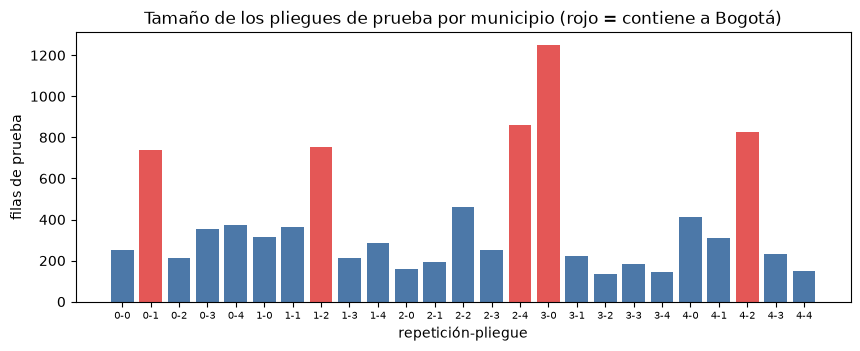

,count,mean,std,min,25%,50%,75%,max
contiene_bogota,,,,,,,,
False,20.0000,260.4500,94.7409,133.0000,190.0000,241.5000,322.7500,463.0000
True,5.0000,886.2000,209.4581,739.0000,755.0000,826.0000,861.0000,1250.0000


In [9]:
tam = pd.read_csv(R / "arranque_frio_pliegues.csv")
fig, ax = plt.subplots(figsize=(10, 3.5))
colores = np.where(tam.contiene_bogota, "#e45756", "#4c78a8")
ax.bar(range(len(tam)), tam.n_prueba, color=colores)
ax.set_xticks(range(len(tam)), [f"{r}-{k}" for r, k in zip(tam.repeticion, tam.pliegue)], fontsize=7)
ax.set_xlabel("repetición-pliegue"); ax.set_ylabel("filas de prueba"); ax.set_title("Tamaño de los pliegues de prueba por municipio (rojo = contiene a Bogotá)")
plt.show()
display(tam.groupby("contiene_bogota").n_prueba.describe())

In [10]:
# Resultados por municipio frente a la confirmación por IES de la Tarea 2
frio = pd.read_csv(R / "arranque_frio_municipio_resumen.csv")
ies = pd.read_csv(p["confirmacion_tarea2"]).set_index("configuracion")
tabla = frio.assign(mae_por_ies=frio.configuracion.map(ies.mae_media), mejora_por_ies_pct=frio.configuracion.map(ies.mejora_grupo_pct))
display(tabla[["configuracion", "mae_media", "mae_ic_inf", "mae_ic_sup", "mae_por_ies", "mejora_grupo_pct", "mejora_por_ies_pct", "p_wilcoxon_grupo", "p_t_grupo"]].sort_values("mae_media").reset_index(drop=True))

,configuracion,mae_media,mae_ic_inf,mae_ic_sup,mae_por_ies,mejora_grupo_pct,mejora_por_ies_pct,p_wilcoxon_grupo,p_t_grupo
0,base_mediana_grupo,0.0373,0.0292,0.0454,0.0405,0.0000,0.0000,NaN,NaN
1,xgboost | logit | mediana | ninguna | con clusters,0.0375,0.0282,0.0468,0.0453,-0.5410,-11.8326,0.3957,0.9017
2,ridge | logit | mediana | info_mutua | sin clusters,0.0376,0.0266,0.0485,0.0396,-0.6461,2.1995,0.9789,0.9177
3,random_forest | logit | mediana | ninguna | con clusters,0.0380,0.0289,0.0471,0.0478,-1.8374,-17.9443,0.2411,0.6785
4,ridge | logit | mediana | ninguna | sin clusters,0.0385,0.0260,0.0510,0.0399,-3.1889,1.4579,0.5782,0.7336
5,ridge | logit | mediana | pca | sin clusters,0.0425,0.0293,0.0557,0.0454,-13.9637,-12.0465,0.0000,0.1904
6,ridge | logit | mediana | kernel_pca | sin clusters,0.0435,0.0331,0.0540,0.0461,-16.6849,-13.7684,0.0000,0.0041
7,ridge | logit | knn | autoencoder | sin clusters,0.0444,0.0335,0.0553,0.0458,-18.9838,-13.0861,0.0000,0.0025
8,base_mediana,0.0468,0.0363,0.0572,0.0501,-25.2841,-23.6214,0.0000,0.0001


## 5. Conclusión

(Tomada de `reports/04_ajuste_temporal.md`; todas las cifras salen de la corrida.)

**1. ¿El ajuste de hiperparámetros cambia alguna conclusión?** (validación anidada, 25 ajustes por configuración; diferencia positiva = menos error)
- `C solo historia | ridge`: MAE 0,0245 por defecto → 0,0245 ajustado (el ajuste cambia 0,0000 [-0,0003; 0,0004], p t corregida 0,760). Frente a la línea base: por defecto +4,2 % (mejora, significativa en ambas pruebas); ajustado +4,4 % (mejora, significativa en ambas pruebas; p Wilcoxon < 0,001, p t corregida 0,011). No cambia la conclusión («supera»).
- `C solo historia | random_forest`: MAE 0,0257 por defecto → 0,0245 ajustado (el ajuste cambia 0,0012 [-0,0002; 0,0026], p t corregida 0,082). Frente a la línea base: por defecto -0,4 % (no mejora, sin significancia); ajustado +4,3 % (mejora; significativa solo en Wilcoxon, que no corrige la dependencia; p Wilcoxon < 0,001, p t corregida 0,057). No cambia la conclusión («sin diferencia firme»).
- `C solo historia | xgboost`: MAE 0,0257 por defecto → 0,0250 ajustado (el ajuste cambia 0,0007 [-0,0007; 0,0021], p t corregida 0,333). Frente a la línea base: por defecto -0,3 % (no mejora, sin significancia); ajustado +2,3 % (mejora; significativa solo en Wilcoxon, que no corrige la dependencia; p Wilcoxon 0,020, p t corregida 0,359). No cambia la conclusión («sin diferencia firme»).
- `B historia+contexto | xgboost logit`: MAE 0,0258 por defecto → 0,0250 ajustado (el ajuste cambia 0,0009 [-0,0004; 0,0022], p t corregida 0,184). Frente a la línea base: por defecto -0,8 % (no mejora, sin significancia); ajustado +2,6 % (mejora, sin significancia; p Wilcoxon 0,080, p t corregida 0,496). No cambia la conclusión («sin diferencia firme»).
- `ridge | logit | mediana | info_mutua | sin clusters`: MAE 0,0396 por defecto → 0,0396 ajustado (el ajuste cambia -0,0001 [-0,0004; 0,0003], p t corregida 0,709). Frente a la línea base: por defecto +1,1 % (mejora, sin significancia); ajustado +0,9 % (mejora, sin significancia; p Wilcoxon 0,127, p t corregida 0,596). No cambia la conclusión («sin diferencia firme»).
- `xgboost | logit | mediana | ninguna | con clusters`: MAE 0,0448 por defecto → 0,0407 ajustado (el ajuste cambia 0,0042 [0,0025; 0,0058], p t corregida < 0,001). Frente a la línea base: por defecto -12,1 % (empeora, significativa en ambas pruebas); ajustado -1,7 % (no mejora, sin significancia; p Wilcoxon 0,096, p t corregida 0,522). **Cambia la conclusión** (de «empeora» a «sin diferencia firme»).
- `random_forest | logit | mediana | ninguna | con clusters`: MAE 0,0469 por defecto → 0,0398 ajustado (el ajuste cambia 0,0070 [0,0038; 0,0103], p t corregida < 0,001). Frente a la línea base: por defecto -17,1 % (empeora, significativa en ambas pruebas); ajustado +0,4 % (mejora, sin significancia; p Wilcoxon 0,474, p t corregida 0,804). **Cambia la conclusión** (de «empeora» a «sin diferencia firme»).
  El ajuste mejora de forma significativa (t corregida < 0,05) a su versión por defecto en 2 de 7 configuraciones: `xgboost | logit | mediana | ninguna | con clusters`, `random_forest | logit | mediana | ninguna | con clusters`.
  «Cambia la conclusión» significa que cambia la clase frente a la línea base (`supera`, `empeora` o `sin diferencia firme`, exigiendo significancia en las dos pruebas): ocurre en 2 de 7 configuraciones; superan a su línea base con significancia en las dos pruebas: `C solo historia | ridge`.

**2. ¿La ventaja de la naive se mantiene en años futuros y en pandemia?** (Tarea 1, pronóstico a un paso con la tasa observada de t-1; bootstrap sobre IES, diferencia = MAE de la naive − MAE del modelo ajustado; positiva = gana el modelo)
- **Prepandemia (entrena 2015–2017, prueba 2018–2019):** la naive tiene MAE 0,0226 [0,0188; 0,0269].
  - `C solo historia | ridge`: MAE 0,0214; diferencia 0,0012 [-0,0002; 0,0026]: no distinguible (el IC incluye 0).
  - `C solo historia | random_forest`: MAE 0,0228; diferencia -0,0002 [-0,0019; 0,0015]: no distinguible (el IC incluye 0).
  - `C solo historia | xgboost`: MAE 0,0235; diferencia -0,0008 [-0,0023; 0,0006]: no distinguible (el IC incluye 0).
  - `B historia+contexto | xgboost logit`: MAE 0,0231; diferencia -0,0005 [-0,0028; 0,0018]: no distinguible (el IC incluye 0).
- **Estrés (entrena 2015–2019, prueba 2020–2021):** la naive tiene MAE 0,0237 [0,0194; 0,0289].
  - `C solo historia | ridge`: MAE 0,0239; diferencia -0,0002 [-0,0019; 0,0014]: no distinguible (el IC incluye 0).
  - `C solo historia | random_forest`: MAE 0,0230; diferencia 0,0007 [-0,0006; 0,0021]: no distinguible (el IC incluye 0).
  - `C solo historia | xgboost`: MAE 0,0233; diferencia 0,0004 [-0,0008; 0,0016]: no distinguible (el IC incluye 0).
  - `B historia+contexto | xgboost logit`: MAE 0,0251; diferencia -0,0014 [-0,0032; 0,0005]: no distinguible (el IC incluye 0).
- **Resumen:** en 8 de 8 comparaciones (modelo ajustado frente a la naive, por partición) el IC 95 % de la diferencia incluye 0: ningún modelo ajustado se distingue de la naive ni antes ni durante la pandemia. La naive misma pasa de MAE 0,0226 a 0,0237 en pandemia, es decir, se mantiene competitiva en años futuros y en pandemia.

**3. ¿En 2020–2021 alguna línea base o modelo se degrada más?** (razón entre el MAE del estrés y el de la prepandemia, con el entrenamiento ajustado en cada partición; los entrenamientos son distintos)
- **Tarea 1:** la mayor degradación es la de `base_mediana` (×1,15; MAE 0,0440 → 0,0506). Entre las líneas base, la que más se degrada es `base_mediana` (×1,15); entre los modelos, `C solo historia | ridge` (×1,12). Los modelos se degradan entre ×0,99 y ×1,12; las líneas base, entre ×1,05 y ×1,15.
- **Tarea 2:** la mayor degradación es la de `xgboost | logit | mediana | ninguna | con clusters` (×1,17; MAE 0,0335 → 0,0393). Entre las líneas base, la que más se degrada es `T2 base_mediana` (×1,15); entre los modelos, `xgboost | logit | mediana | ninguna | con clusters` (×1,17). Los modelos se degradan entre ×0,61 y ×1,17; las líneas base, entre ×1,14 y ×1,15.
- **Atención, `ridge | logit | mediana | info_mutua | sin clusters`:** su razón ×0,61 no es una mejora en pandemia: su MAE de la prepandemia (0,0642) es muy superior al de su versión por defecto (0,0360), es decir, el ajuste degradó ese modelo al predecir 2018–2019 (ver la tabla de error por subgrupo, con Bogotá aparte, y la nota de diagnóstico).
- MAE de la naive (Tarea 1) por año de prueba: 2018: 0,0264, 2019: 0,0188, 2020: 0,0205, 2021: 0,0269.

**4. ¿Agrupar por municipio cambia la Tarea 2?** (confirmación 5 × 5 con GroupKFold por municipio sede; ninguna ciudad de prueba aparece en el entrenamiento)
- La mediana por carácter × sector pasa de MAE 0,0405 (por IES) a 0,0373 (por municipio). 0 de 7 configuraciones superan a esa línea base con significancia en las dos pruebas. La de menor MAE por municipio es `xgboost | logit | mediana | ninguna | con clusters`: 0,0375 [0,0282; 0,0468] (-0,5 %; p Wilcoxon 0,396, p t corregida 0,902); por IES esa misma configuración tenía -11,8 %.
- **Respuesta:** agrupar por municipio no cambia la conclusión principal de la Tarea 2: ningún modelo supera con firmeza a la mediana por carácter × sector. Mejora frente a la mediana por carácter × sector (la línea base se recalcula con cada agrupación): `ridge | logit | mediana | info_mutua | sin clusters`: +2,2 % por IES → -0,6 % por municipio; `xgboost | logit | mediana | ninguna | con clusters`: -11,8 % por IES → -0,5 % por municipio; `random_forest | logit | mediana | ninguna | con clusters`: -17,9 % por IES → -1,8 % por municipio; `ridge | logit | mediana | ninguna | sin clusters`: +1,5 % por IES → -3,2 % por municipio; `ridge | logit | mediana | pca | sin clusters`: -12,0 % por IES → -14,0 % por municipio; `ridge | logit | knn | autoencoder | sin clusters`: -13,1 % por IES → -19,0 % por municipio; `ridge | logit | mediana | kernel_pca | sin clusters`: -13,8 % por IES → -16,7 % por municipio.
- Bogotá desbalancea los pliegues: el pliegue que la contiene tiene entre 739 y 1250 filas de prueba (38 % a 65 % del total), frente a 133–463 en los demás; cuando Bogotá está en la prueba, el entrenamiento no tiene ninguna fila de Bogotá.